# Group model: quantile neural networks for Q0 financial prediction


This notebook contains the final group workflow. It evaluates six model families on shared folds, reserves a locked holdout, and selects a quantile neural network with an sMAPE-aware decision layer and accounting-identity post-processing.


## 1. Config

In [2]:
import os, re, time, pickle, gc, warnings
import numpy as np, pandas as pd, xgboost as xgb
import matplotlib.pyplot as plt
from itertools import product
from sklearn.model_selection import KFold, train_test_split
from tqdm.auto import tqdm
from IPython.display import display
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)

from pathlib import Path
WORKING_DIR = Path.cwd().resolve()
REPO_ROOT = WORKING_DIR.parent if WORKING_DIR.name == "notebooks" else WORKING_DIR
DATA_DIR = REPO_ROOT / "data" / "raw"
ARTIFACT_DIR = REPO_ROOT / "artifacts"
OUTPUT_DIR = REPO_ROOT / "outputs"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED       = 42
QUICK      = False       # True = fast check pass (20k rows, fewer trees). Do this once first.
DEV_ROWS   = None        # None = all 100k
N_FOLDS    = 5
HOLD_FRAC  = 0.2
RESULTS    = str(ARTIFACT_DIR / "group_results.pkl")

RUN = {"xgboost": True, "mlp_l1": True, "mlp_smape": True,
       "mlp_quantile": True, "multitask": True, "gru": True, "stack": True}
USE_IDENTITIES  = True   # per target, allow swapping in the accounting-identity form (a plain either/or)
PER_TARGET_BEST = True   # True: best model per target. False: one model for all nine.
N_SEEDS    = 1           # >1 averages that many seeds per neural model
QUANTILES  = list(np.round(np.linspace(0.02, 0.98, 25), 4))   # denser grid = better distribution estimate
SPREADS    = [0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.25, 1.5, 1.75, 2.0]   # per-target calibration of predictive spread (chosen on dev)
CAND_GRID  = 121         # dense candidate points spanned per row, on top of the quantiles themselves
CHUNK      = 4000        # rows per chunk in the decision layer
IDENTITY_PENALTY = 0.3   # weight on identity residuals in the multitask loss
XGB_TREES  = 900
MLP_EPOCHS = 60
if QUICK:
    DEV_ROWS, XGB_TREES, RESULTS = 20000, 300, "results_quick.pkl"
T_START = time.time()

TARGET_VARS = ["TOTAL_ASSETS", "TOTAL_LIABILITIES", "TOTAL_STOCKHOLDERS_EQUITY",
               "GROSS_PROFIT", "COST_OF_REVENUES", "REVENUES",
               "OPERATING_INCOME", "OPERATING_EXPENSES", "EBITDA"]
ALL_VARS = TARGET_VARS + ["TOTAL_CURRENT_ASSETS", "TOTAL_NONCURRENT_ASSETS",
                          "TOTAL_CURRENT_LIABILITIES", "TOTAL_NONCURRENT_LIABILITIES",
                          "TOTAL_LIABILITIES_AND_EQUITY", "NET_INCOME",
                          "DEPRECIATION_AND_AMORTIZATION"]
CATS  = ["industry", "sector", "recommendationKey", "financialCurrency"]
MONEY = ["totalCash", "ebitda", "totalDebt", "totalRevenue", "freeCashflow", "operatingCashflow"]
FIT_VARS = TARGET_VARS + ["DA0"]     # DA0 = Q0 D&A, used for the EBITDA identity


def smape(y, p):
    d = (np.abs(y) + np.abs(p)) / 2
    return 100 * np.mean(np.where(d == 0, 0.0, np.abs(y - p) / np.where(d == 0, 1.0, d)))


def has_gpu():
    # xgboost >= 2.1 silently falls back to CPU with only a warning, so check for the warning
    try:
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always")
            xgb.XGBRegressor(device="cuda", tree_method="hist", n_estimators=1).fit(np.zeros((8, 2)), np.zeros(8))
        msgs = " ".join(str(x.message).lower() for x in w)
        return not any(k in msgs for k in ["no visible gpu", "changed from gpu to cpu", "falling back"])
    except Exception:
        return False

GPU = has_gpu()
print("xgboost", xgb.__version__, "| device:", "cuda" if GPU else "cpu (switch the runtime to GPU)")

xgboost 3.2.0 | device: cuda


In [ ]:
TRAIN_PATHS = [DATA_DIR / name for name in ("train.csv", "train2.csv")]
TEST_PATH = DATA_DIR / "test_final.csv"
missing = [str(path) for path in [*TRAIN_PATHS, TEST_PATH] if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Missing dataset files. See data/README.md for setup instructions: "
        + ", ".join(missing)
    )
print("train:", [path.name for path in TRAIN_PATHS], "| test:", TEST_PATH.name)


## 2. Load

In [4]:
norm = lambda c: re.sub(r"\s+", "_", c.strip())
head = pd.read_csv(TRAIN_PATHS[0], nrows=5)
orig_name = {norm(c): c for c in head.columns}
dtypes = {c: (str if norm(c) in CATS else np.float32) for c in head.columns if norm(c).lower() != "id"}

# train.csv (100k) + train2.csv (50k, the first round's test set with labels revealed).
# Verified: same generator, no overlapping Ids, no duplicate rows within or across them.
train = pd.concat([pd.read_csv(p, dtype=dtypes, nrows=DEV_ROWS).rename(columns=norm) for p in TRAIN_PATHS],
                  ignore_index=True)
test  = pd.read_csv(TEST_PATH, dtype=dtypes).rename(columns=norm)
if len(TRAIN_PATHS) > 1:
    print(f"combined {len(TRAIN_PATHS)} training files -> {len(train):,} rows")
ID = [c for c in test.columns if c.lower() == "id"][0]
TARGETS = ["Q0_" + v for v in TARGET_VARS]
print("train", train.shape, "| test", test.shape)
assert train.duplicated(subset=[c for c in train.columns if c.lower() != "id"]).sum() == 0, "duplicate training rows"
print("Q0 columns usable as features:", [c for c in test.columns if c.startswith("Q0_")])

# --- split FIRST, before any look at the data ---
ntr = len(train)
rng = np.random.default_rng(0)
hold_mask = rng.random(ntr) < HOLD_FRAC
dev_idx, hold_idx = np.where(~hold_mask)[0], np.where(hold_mask)[0]
FOLDS = list(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(dev_idx))
dev_rows = train.iloc[dev_idx]          # the ONLY slice EDA and preprocessing may touch
print(f"dev {len(dev_idx):,} | locked holdout {len(hold_idx):,}")

combined 2 training files -> 150,000 rows
train (150000, 212) | test (50000, 203)
Q0 columns usable as features: ['Q0_fiscal_year_end']
dev 119,973 | locked holdout 30,027


## 3. EDA (development rows only)

Every statistic below is computed on `dev_rows`. The holdout is not inspected, in aggregate or otherwise, so the modelling decisions that follow are independent of it.

In [5]:
print("NaN cells in dev:", int(dev_rows.isna().sum().sum()))
sent = []
for c in dev_rows.select_dtypes("number").columns:
    v = dev_rows[c].value_counts()
    if len(v) and v.iloc[0] > 0.01 * len(dev_rows) and "fiscal" not in c:
        sent.append((c, float(v.index[0]), int(v.iloc[0])))
display(pd.DataFrame(sent, columns=["column", "repeated value", "rows"])
        .sort_values("rows", ascending=False).head(12).reset_index(drop=True))
print("^ heavily repeated values. Several equal the column median on ~18% of rows, which is consistent with")
print("  pre-release median imputation, though repetition alone doesn't prove it - so these are FLAGGED, not nulled.")

NaN cells in dev: 0


,column,repeated value,rows
0,overallRisk,6.000000,34354
1,auditRisk,6.000000,33649
2,shareHolderRightsRisk,6.000000,33390
3,compensationRisk,6.000000,33341
4,boardRisk,6.000000,33321
5,numberOfAnalystOpinions,6.000000,15071
6,targetHighPrice,30.000000,14990
7,targetLowPrice,17.000000,14917
8,targetMedianPrice,23.000000,14917
9,targetMeanPrice,23.100000,14917


^ heavily repeated values. Several equal the column median on ~18% of rows, which is consistent with
  pre-release median imputation, though repetition alone doesn't prove it - so these are FLAGGED, not nulled.


In [6]:
rows = []
for v in TARGET_VARS:
    y = dev_rows["Q0_" + v].to_numpy(float)
    for q in (1, 3, 4):
        x = dev_rows[f"Q{q}_{v}"].to_numpy(float)
        r = np.median(y / np.where(x == 0, np.nan, x))
        rows.append(dict(var=v, lag=f"Q{q}", ratio=r, sMAPE=smape(y, r * x),
                         sign_match=np.mean(np.sign(y) == np.sign(x))))
display(pd.DataFrame(rows).pivot(index="var", columns="lag", values=["ratio", "sMAPE", "sign_match"])
        .style.format("{:.2f}").set_caption("Q0 vs each lag: median ratio, sMAPE of ratio*lag, sign agreement"))

d = dev_rows
print("Q0: OI vs GP - OPEX        ", smape(d.Q0_OPERATING_INCOME, d.Q0_GROSS_PROFIT - d.Q0_OPERATING_EXPENSES))
print("Q0: ASSETS vs LIAB + EQ    ", smape(d.Q0_TOTAL_ASSETS, d.Q0_TOTAL_LIABILITIES + d.Q0_TOTAL_STOCKHOLDERS_EQUITY))
print("Q0: GP vs REV - COGS       ", smape(d.Q0_GROSS_PROFIT, d.Q0_REVENUES - d.Q0_COST_OF_REVENUES))
print("Q1: OI vs GP - OPEX        ", smape(d.Q1_OPERATING_INCOME, d.Q1_GROSS_PROFIT - d.Q1_OPERATING_EXPENSES))
print("Q1: EBITDA vs OI + D&A     ", smape(d.Q1_EBITDA, d.Q1_OPERATING_INCOME + d.Q1_DEPRECIATION_AND_AMORTIZATION))

Q0: OI vs GP - OPEX         4.0409654e-05
Q0: ASSETS vs LIAB + EQ     1.9446309e-06
Q0: GP vs REV - COGS        2.8052628
Q1: OI vs GP - OPEX         43.374283
Q1: EBITDA vs OI + D&A      0.061331246


## 4. Clean and build features

Learned statistics (the sentinel values, the category vocabularies, the scale fallback) are estimated on development rows only and then applied unchanged to holdout and test. Row-wise arithmetic - a row's lags divided by that row's own scale - uses no shared statistics and is fine anywhere.

In [7]:
Y = train[TARGETS].astype(float)
Y["DA0"] = Y["Q0_EBITDA"] - Y["Q0_OPERATING_INCOME"]
full = pd.concat([train.drop(columns=TARGETS), test], ignore_index=True)
test_ids = test[ID].values
del train, dev_rows, test; gc.collect()
DEV = full.index[dev_idx]                     # dev rows inside `full`

clean = lambda s: (s.astype(str).str.strip().str.lower()
                   .replace({"missing": np.nan, "nan": np.nan, "none": np.nan, "": np.nan}))
for c in CATS:
    col = clean(full[c])
    vocab = sorted(col.loc[DEV].dropna().unique())        # vocabulary learned on dev only
    full[c] = pd.Categorical(col.where(col.isin(vocab)), categories=vocab)   # unseen level -> NaN

# Sentinel columns: FLAG the repeated value, keep the value itself. Repetition is suggestive of
# pre-release imputation but not proof, so nothing is discarded. Values come from dev rows only.
flags = {}
for c, val, _ in sent:
    if c in full.columns:
        flags[c + "_imputed"] = (full[c] == val).astype(np.float32)
flags = pd.DataFrame(flags)
print(f"{flags.shape[1]} sentinel flags added (values kept, not nulled)")


def own_scale(v):
    s = full[[f"Q{q}_{v}" for q in range(1, 5)]].abs().median(axis=1)
    return s.where(s > 0)

asset_scale = own_scale("TOTAL_ASSETS")
asset_scale = asset_scale.fillna(asset_scale.loc[DEV].median())    # fallback estimated on dev only
lag_cols = [f"Q{q}_{v}" for q in range(1, 11) for v in ALL_VARS]
extras = [c for c in full.columns if c not in lag_cols + CATS + [ID]]
sh = {"log_size": np.log10(asset_scale)}
for u in ALL_VARS:
    su = own_scale(u)
    sh[f"qoq_{u}"] = (full[f"Q1_{u}"] - full[f"Q2_{u}"]) / su
    sh[f"yoy_{u}"] = (full[f"Q1_{u}"] - full[f"Q5_{u}"]) / su
shared = pd.concat([pd.DataFrame(sh), full[extras], flags, full[CATS]], axis=1)
MONEY = [c for c in MONEY if c in full.columns]


def build(v):
    """Scale-free features for target v. Returns X (train rows then test rows), base (latest lag), scale."""
    anchor = "EBITDA" if v == "DA0" else v
    L = full[[f"Q{q}_{anchor}" for q in range(1, 11)]]
    base_ = L.bfill(axis=1).iloc[:, 0]
    s = own_scale(anchor).fillna(base_.abs().where(base_.abs() > 0)).fillna(asset_scale)
    s = np.maximum(s, 1e-3 * asset_scale); base_ = base_.fillna(0.0)
    f = {f"lag{q}": full[f"Q{q}_{anchor}"] / s for q in range(1, 11)}
    for u in ALL_VARS:
        if u != anchor:
            for q in (1, 2):
                f[f"{u}_q{q}"] = full[f"Q{q}_{u}"] / s
    q1, q4, q5 = full[f"Q1_{anchor}"], full[f"Q4_{anchor}"], full[f"Q5_{anchor}"]
    f["seas_add"]  = (q4 + q1 - q5 - base_) / s
    f["seas_mult"] = (q4 * q1 / q5.where(q5 != 0) - base_) / s
    for m in MONEY:
        f[f"{m}_sc"] = full[m] / s
    f["log_s"] = np.log10(s)
    F = pd.DataFrame(f).astype(np.float32)
    X = pd.concat([F, shared], axis=1).replace([np.inf, -np.inf], np.nan)
    return X, base_.to_numpy(float), s.to_numpy(float)

print("features per target:", build("REVENUES")[0].shape[1])

24 sentinel flags added (values kept, not nulled)
features per target: 148


## 5. Harness

The split already happened in section 2. The harness owns the transform and the scoring. A model supplies
`fit_predict(X_train, z_train, [X_val, X_hold, X_test], aux) -> [pred_val, pred_hold, pred_test]`
on the z scale. `aux` carries the per-row anchor and scale for each block, which the sMAPE-loss and quantile
models need in order to reason on the original scale. Holdout and test predictions are averaged over the fold models. Early stopping inside
a model must use an inner split of `X_train`, never `X_val`.

In [8]:
# Cache key includes the data, split and feature set: change any of them and the cache is a new file,
# so stale predictions can never be silently reused.
import hashlib, json
FP = hashlib.md5(json.dumps({"rows": int(ntr), "folds": N_FOLDS, "hold": float(HOLD_FRAC), "seed": SEED,
                             "feats": list(build("REVENUES")[0].columns),
                             "dev": int(dev_idx.sum())}, sort_keys=True).encode()).hexdigest()[:8]
RESULTS = RESULTS.replace(".pkl", f"_{FP}.pkl")
RES = pickle.load(open(RESULTS, "rb")) if os.path.exists(RESULTS) else {}
print(f"dev {len(dev_idx):,} | locked holdout {len(hold_idx):,} | cache {RESULTS} ({len(RES)} entries)")


def label(v):
    return Y["DA0" if v == "DA0" else "Q0_" + v].to_numpy(float)


def run_model(name, fit_predict, v):
    if (name, v) in RES:
        return RES[(name, v)]
    t0 = time.time()
    X, base_, s = build(v)
    y = label(v)
    b, sc = base_[:ntr], s[:ntr]
    z = np.clip((y - b) / sc, -15, 15)
    Xd, Xh, Xt = X.iloc[dev_idx], X.iloc[hold_idx], X.iloc[ntr:]
    zd, bd, sd = z[dev_idx], b[dev_idx], sc[dev_idx]
    oof = np.zeros(len(dev_idx)); zh = np.zeros(len(hold_idx)); zt = np.zeros(len(Xt)); fs = []
    for a, va in FOLDS:
        aux = dict(b_tr=bd[a], s_tr=sd[a],
                   b=[bd[va], b[hold_idx], base_[ntr:]], s=[sd[va], sc[hold_idx], s[ntr:]])
        pv, ph, pt = fit_predict(Xd.iloc[a], zd[a], [Xd.iloc[va], Xh, Xt], aux)
        oof[va] = pv; zh += ph / N_FOLDS; zt += pt / N_FOLDS
        fs.append(smape(y[dev_idx][va], bd[va] + sd[va] * pv))
    r = dict(oof=bd + sd * oof, hold=b[hold_idx] + sc[hold_idx] * zh, test=base_[ntr:] + s[ntr:] * zt,
             cv=smape(y[dev_idx], bd + sd * oof), se=np.std(fs, ddof=1) / np.sqrt(N_FOLDS),
             secs=time.time() - t0)
    RES[(name, v)] = r
    pickle.dump(RES, open(RESULTS, "wb"))
    print(f"{name:10s} {v:28s} CV {r['cv']:7.2f} ± {r['se']:.2f}   [{r['secs']:.0f}s]", flush=True)
    del X; gc.collect()
    return r


RES_MODELS = lambda: [m for m in sorted({m for m, _ in RES}) if m not in ("naive", "persist")]

# baselines, computed with the same folds
for v in FIT_VARS:
    y = label(v); yd = y[dev_idx]
    oof = np.zeros(len(yd))
    for a, va in FOLDS:
        oof[va] = yd[a].mean()
    RES[("naive", v)] = dict(oof=oof, hold=np.full(len(hold_idx), yd.mean()), test=np.full(len(full) - ntr, yd.mean()),
                             cv=smape(yd, oof), se=np.nan)
    lag = full[f"Q1_{'EBITDA' if v == 'DA0' else v}"].to_numpy(float)
    RES[("persist", v)] = dict(oof=lag[dev_idx], hold=lag[hold_idx], test=lag[ntr:], cv=smape(yd, lag[dev_idx]), se=np.nan)

dev 119,973 | locked holdout 30,027 | cache results_e0e60faf.pkl (0 entries)


## 6. XGBoost

In [9]:
xgb_params = dict(objective="reg:absoluteerror", n_estimators=XGB_TREES, learning_rate=0.05,
                  max_depth=0, grow_policy="lossguide", max_leaves=63, max_bin=64,
                  min_child_weight=40, subsample=0.8, colsample_bytree=0.4, reg_lambda=1.0,
                  tree_method="hist", device="cuda" if GPU else "cpu",
                  enable_categorical=True, max_cat_to_onehot=1,
                  random_state=SEED, early_stopping_rounds=50, verbosity=0)


def xgb_fp(Xa, za, Xs, aux):
    Xi, Xe, zi, ze = train_test_split(Xa, za, test_size=0.1, random_state=SEED)   # inner split
    m = xgb.XGBRegressor(**xgb_params).fit(Xi, zi, eval_set=[(Xe, ze)], verbose=False)
    return [m.predict(X) for X in Xs]

if RUN["xgboost"]:
    for v in tqdm(FIT_VARS, desc="xgboost"):
        run_model("xgboost", xgb_fp, v)

xgboost:   0%|          | 0/10 [00:00<?, ?it/s]

xgboost    TOTAL_ASSETS                 CV    1.54 ± 0.04   [116s]
xgboost    TOTAL_LIABILITIES            CV    3.17 ± 0.03   [114s]
xgboost    TOTAL_STOCKHOLDERS_EQUITY    CV    4.52 ± 0.05   [116s]
xgboost    GROSS_PROFIT                 CV   16.96 ± 0.07   [115s]
xgboost    COST_OF_REVENUES             CV    6.51 ± 0.05   [115s]
xgboost    REVENUES                     CV    5.82 ± 0.02   [114s]
xgboost    OPERATING_INCOME             CV   41.00 ± 0.16   [114s]
xgboost    OPERATING_EXPENSES           CV    2.21 ± 0.01   [116s]
xgboost    EBITDA                       CV   39.11 ± 0.18   [114s]
xgboost    DA0                          CV   39.60 ± 0.14   [115s]


## 7. Neural models

Four models share one trainer; the head and the loss are what differ.

- `mlp_l1` — one output, L1 on `z`. The baseline.
- `mlp_smape` — one output, but the loss is a soft sMAPE on the reconstructed `y = base + scale*z`, so
  training optimises the metric itself. Its saturation also stops the model spending capacity on rows it
  cannot get right.
- `mlp_quantile` — one output per quantile, pinball loss, giving a predictive distribution per row. The
  point estimate is then chosen to minimise *expected* sMAPE under that distribution. This matters because
  sMAPE is not minimised by the conditional median: it saturates at 200% for a sign error and blows up near
  zero, so on sign-unstable targets like operating income the best point can sit well away from the middle.
- `gru` — the flat lag columns are reshaped back to (10 quarters, 16 variables) and read by a GRU, so
  seasonality and trend are learned rather than hand-coded as `seas_add` / `seas_mult`.

In [10]:
import torch, torch.nn as nn
TDEV = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "|", TDEV)

sector_oh = pd.get_dummies(full["sector"], prefix="sec", dtype=np.float32)   # dev vocabulary
SEQ_VARS = ALL_VARS


def to_matrix(X):
    return pd.concat([X.drop(columns=CATS).astype(np.float32), sector_oh.loc[X.index]], axis=1).to_numpy(np.float32)


def prep_blocks(Xa, Xs):
    # signed-log -> median impute (+ NaN flags) -> standardise -> clip. Statistics come from Xa only.
    sl = lambda A: np.sign(A) * np.log1p(np.abs(A))
    A = sl(to_matrix(Xa)); Bs = [sl(to_matrix(X)) for X in Xs]
    med = np.nan_to_num(np.nanmedian(A, axis=0))
    fill = lambda M: np.hstack([np.where(np.isnan(M), med, M), np.isnan(M).astype(np.float32)])
    A = fill(A); Bs = [fill(B) for B in Bs]
    mu, sd = A.mean(0), A.std(0) + 1e-6
    std = lambda M: np.clip((M - mu) / sd, -6, 6).astype(np.float32)
    return std(A), [std(B) for B in Bs]


def seq_blocks(X_list, anchor):
    # (rows, 10 quarters, 16 variables) from the scale-free lag columns already in X
    def one(X):
        M = np.zeros((len(X), 10, len(SEQ_VARS)), dtype=np.float32)
        for k, u in enumerate(SEQ_VARS):
            for q in range(1, 11):
                c = f"lag{q}" if u == anchor else f"{u}_q{q}"
                if c in X.columns:
                    M[:, q - 1, k] = X[c].to_numpy(np.float32)
        return np.nan_to_num(np.sign(M) * np.log1p(np.abs(M)), nan=0.0, posinf=0.0, neginf=0.0)
    return [one(X) for X in X_list]


def soft_smape(pred_y, true_y, eps=1e-6):
    den = torch.clamp((pred_y.abs() + true_y.abs()) / 2, min=eps)
    return ((pred_y - true_y).abs() / den).mean()


def pinball(pred, target, qs):
    e = target.unsqueeze(1) - pred
    return torch.max(qs * e, (qs - 1) * e).mean()


def make_mlp(n_in, n_out):
    net = nn.Sequential(nn.Linear(n_in, 256), nn.SiLU(), nn.Dropout(0.15),
                        nn.Linear(256, 128), nn.SiLU(), nn.Dropout(0.15), nn.Linear(128, n_out))
    nn.init.zeros_(net[-1].weight); nn.init.zeros_(net[-1].bias)     # start at persistence
    return net


class GRUNet(nn.Module):
    def __init__(self, n_vars, n_static):
        super().__init__()
        self.gru = nn.GRU(n_vars, 96, batch_first=True)
        self.head = nn.Sequential(nn.Linear(96 + n_static, 128), nn.SiLU(), nn.Dropout(0.1),
                                  nn.Linear(128, 1))
        nn.init.zeros_(self.head[-1].weight); nn.init.zeros_(self.head[-1].bias)

    def forward(self, seq, static):
        return self.head(torch.cat([self.gru(seq)[0][:, -1], static], 1))


def torch_train(net, ins_tr, z_tr, ins_eval, loss_kind, aux, seed=SEED, epochs=None):
    # generic loop; ins_* are lists of arrays fed positionally to the net. Early stopping on an inner split.
    epochs = epochs or MLP_EPOCHS
    torch.manual_seed(seed)
    n = len(z_tr)
    perm0 = np.random.default_rng(seed).permutation(n)
    cut = int(0.9 * n); tr_i, ev_i = perm0[:cut], perm0[cut:]
    T = lambda A: torch.tensor(np.ascontiguousarray(A), device=TDEV)
    tr_in = [T(A[tr_i]) for A in ins_tr]; ev_in = [T(A[ev_i]) for A in ins_tr]
    zs = float(np.mean(np.abs(z_tr)) + 1e-9)
    z_all = (z_tr / zs).astype(np.float32)
    z_tr_t, z_ev_t = T(z_all[tr_i]), T(z_all[ev_i])
    b_tr_t, b_ev_t = T(aux["b_tr"][tr_i].astype(np.float32)), T(aux["b_tr"][ev_i].astype(np.float32))
    s_tr_t, s_ev_t = T(aux["s_tr"][tr_i].astype(np.float32)), T(aux["s_tr"][ev_i].astype(np.float32))
    qs = T(np.array(QUANTILES, dtype=np.float32)).view(1, -1)
    net = net.to(TDEV)
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)

    def loss_of(out, zi, bi, si):
        if loss_kind == "l1":
            return nn.functional.l1_loss(out.squeeze(1), zi)
        if loss_kind == "smape":
            return soft_smape(bi + si * out.squeeze(1) * zs, bi + si * zi * zs)
        return pinball(out, zi, qs)

    best, state, bad = np.inf, None, 0
    for _ in range(epochs):
        net.train()
        pm = torch.randperm(len(tr_i), device=TDEV)
        for i in range(0, len(tr_i), 512):
            k = pm[i:i + 512]
            opt.zero_grad()
            loss_of(net(*[A[k] for A in tr_in]), z_tr_t[k], b_tr_t[k], s_tr_t[k]).backward()
            opt.step()
        sched.step(); net.eval()
        with torch.no_grad():
            e = float(loss_of(net(*ev_in), z_ev_t, b_ev_t, s_ev_t))
        if e < best - 1e-7:
            best, bad, state = e, 0, {k: t.clone() for k, t in net.state_dict().items()}
        else:
            bad += 1
            if bad >= 10:
                break
    net.load_state_dict(state); net.eval()
    with torch.no_grad():
        return [net(*[T(A) for A in blk]).cpu().numpy() * zs for blk in ins_eval]


def smape_optimal_point(qy):
    # point minimising expected sMAPE under the sampled predictive distribution qy (rows x quantiles)
    cand = np.concatenate([qy, np.zeros((len(qy), 1), dtype=np.float32)], axis=1)
    den = np.maximum((np.abs(qy)[:, None, :] + np.abs(cand)[:, :, None]) / 2, 1e-12)
    loss = (np.abs(qy[:, None, :] - cand[:, :, None]) / den).mean(2)
    return cand[np.arange(len(qy)), loss.argmin(1)]


def neural_fp(kind, anchor_of):
    def fp(Xa, za, Xs, aux):
        acc = None
        for sd_ in range(N_SEEDS):
            if kind == "gru":
                seqs = seq_blocks([Xa] + list(Xs), anchor_of[0])
                A_seq, B_seqs = seqs[0], seqs[1:]
                A, Bs = prep_blocks(Xa, Xs)
                net = GRUNet(A_seq.shape[2], A.shape[1])
                outs = torch_train(net, [A_seq, A], za, [[b, x] for b, x in zip(B_seqs, Bs)],
                                   "l1", aux, seed=SEED + sd_)
            else:
                A, Bs = prep_blocks(Xa, Xs)
                n_out = len(QUANTILES) if kind == "quantile" else 1
                net = make_mlp(A.shape[1], n_out)
                loss_kind = {"l1": "l1", "smape": "smape", "quantile": "pinball"}[kind]
                outs = torch_train(net, [A], za, [[B] for B in Bs], loss_kind, aux, seed=SEED + sd_)
            acc = outs if acc is None else [x + y for x, y in zip(acc, outs)]
        outs = [x / N_SEEDS for x in acc]
        res = []
        for j, (o, b_, s_) in enumerate(zip(outs, aux["b"], aux["s"])):
            if kind == "quantile":
                qy = (b_[:, None] + s_[:, None] * np.sort(o, axis=1)).astype(np.float32)
                QBUF[j].append(qy)                      # keep the distribution for section 7b
                res.append((smape_optimal_point(qy) - b_) / s_)
            else:
                res.append(o.squeeze(1))
        return res
    return fp

QBUF = {0: [], 1: [], 2: []}       # per-fold buffers: 0 = val rows, 1 = holdout, 2 = test
QS = pickle.load(open("quantiles.pkl", "rb")) if os.path.exists("quantiles.pkl") else {}

for name, kind in [("mlp_l1", "l1"), ("mlp_smape", "smape"), ("mlp_quantile", "quantile"), ("gru", "gru")]:
    if RUN.get(name):
        for v in tqdm(FIT_VARS, desc=name):
            anchor = ["EBITDA" if v == "DA0" else v]
            QBUF = {0: [], 1: [], 2: []}
            run_model(name, neural_fp(kind, anchor), v)
            if kind == "quantile" and v not in QS and QBUF[0]:
                oof_q = np.zeros((len(dev_idx), len(QUANTILES)), np.float32)
                for (a, va), q in zip(FOLDS, QBUF[0]):
                    oof_q[va] = q
                QS[v] = dict(oof=oof_q,
                             hold=np.mean(QBUF[1], 0).astype(np.float32),
                             test=np.mean(QBUF[2], 0).astype(np.float32))
                pickle.dump(QS, open("quantiles.pkl", "wb"))

torch 2.10.0+cu128 | cuda


mlp_l1:   0%|          | 0/10 [00:00<?, ?it/s]

mlp_l1     TOTAL_ASSETS                 CV    1.11 ± 0.01   [90s]
mlp_l1     TOTAL_LIABILITIES            CV    2.83 ± 0.01   [87s]
mlp_l1     TOTAL_STOCKHOLDERS_EQUITY    CV    3.67 ± 0.03   [86s]
mlp_l1     GROSS_PROFIT                 CV   16.24 ± 0.06   [85s]
mlp_l1     COST_OF_REVENUES             CV    5.68 ± 0.04   [86s]
mlp_l1     REVENUES                     CV    4.94 ± 0.01   [86s]
mlp_l1     OPERATING_INCOME             CV   40.66 ± 0.16   [87s]
mlp_l1     OPERATING_EXPENSES           CV    1.92 ± 0.01   [86s]
mlp_l1     EBITDA                       CV   38.64 ± 0.17   [85s]
mlp_l1     DA0                          CV   29.24 ± 0.20   [86s]


mlp_smape:   0%|          | 0/10 [00:00<?, ?it/s]

mlp_smape  TOTAL_ASSETS                 CV    1.44 ± 0.30   [106s]
mlp_smape  TOTAL_LIABILITIES            CV    3.42 ± 0.34   [106s]
mlp_smape  TOTAL_STOCKHOLDERS_EQUITY    CV    3.93 ± 0.03   [106s]
mlp_smape  GROSS_PROFIT                 CV   17.27 ± 0.23   [106s]
mlp_smape  COST_OF_REVENUES             CV    6.14 ± 0.03   [105s]
mlp_smape  REVENUES                     CV    5.04 ± 0.01   [106s]
mlp_smape  OPERATING_INCOME             CV   40.47 ± 0.27   [107s]
mlp_smape  OPERATING_EXPENSES           CV    1.96 ± 0.01   [107s]
mlp_smape  EBITDA                       CV   38.87 ± 0.19   [109s]
mlp_smape  DA0                          CV   54.01 ± 4.05   [83s]


mlp_quantile:   0%|          | 0/10 [00:00<?, ?it/s]

mlp_quantile TOTAL_ASSETS                 CV    1.02 ± 0.01   [98s]
mlp_quantile TOTAL_LIABILITIES            CV    2.78 ± 0.01   [100s]
mlp_quantile TOTAL_STOCKHOLDERS_EQUITY    CV    3.49 ± 0.02   [99s]
mlp_quantile GROSS_PROFIT                 CV   15.91 ± 0.06   [99s]
mlp_quantile COST_OF_REVENUES             CV    5.49 ± 0.04   [100s]
mlp_quantile REVENUES                     CV    4.87 ± 0.01   [100s]
mlp_quantile OPERATING_INCOME             CV   37.35 ± 0.17   [100s]
mlp_quantile OPERATING_EXPENSES           CV    1.77 ± 0.00   [99s]
mlp_quantile EBITDA                       CV   35.63 ± 0.13   [99s]
mlp_quantile DA0                          CV   37.38 ± 0.20   [99s]


gru:   0%|          | 0/10 [00:00<?, ?it/s]

gru        TOTAL_ASSETS                 CV    1.48 ± 0.03   [129s]
gru        TOTAL_LIABILITIES            CV    2.94 ± 0.01   [127s]
gru        TOTAL_STOCKHOLDERS_EQUITY    CV    4.01 ± 0.04   [127s]
gru        GROSS_PROFIT                 CV   16.45 ± 0.05   [129s]
gru        COST_OF_REVENUES             CV    6.08 ± 0.04   [128s]
gru        REVENUES                     CV    5.35 ± 0.02   [127s]
gru        OPERATING_INCOME             CV   41.30 ± 0.18   [127s]
gru        OPERATING_EXPENSES           CV    2.83 ± 0.03   [127s]
gru        EBITDA                       CV   39.08 ± 0.18   [127s]
gru        DA0                          CV   28.74 ± 1.75   [106s]


## 7b. Tuned decision layer

The quantile model won every target, so it's worth separating what it does into two parts: estimating the
predictive distribution, and turning that distribution into a single number. The first part is the network.
The second is a decision rule, and it can be improved without retraining anything.

Three changes over the plain version:

- **Denser candidates.** The optimal point need not be one of the quantiles. Here the candidate set is the
  quantiles, zero, and a dense grid spanning each row's predictive range — including magnitudes smaller than
  any quantile, which is often where the optimum sits when the sign is uncertain.
- **Spread calibration.** A network's quantile heads are usually under-dispersed. Each row's quantiles are
  rescaled around their median by a factor chosen per target on dev, which matters because the decision rule
  is only as good as the distribution it integrates over.
- **Dev-only tuning.** The spread factor is picked on dev out-of-fold predictions, the same place every other
  choice was made. The holdout stays untouched.

Everything here reuses the stored quantile matrices, so it re-runs in seconds without refitting.

In [11]:
def expected_smape_point(qy, n_grid=CAND_GRID, chunk=CHUNK):
    # For each row: candidates = quantiles + 0 + dense grid over the row's range.
    # Pick the candidate minimising mean sMAPE against the row's own predictive sample.
    out = np.empty(len(qy), np.float32)
    for i in range(0, len(qy), chunk):
        q = qy[i:i + chunk]
        lo, hi = q.min(1), q.max(1)
        pad = 0.15 * np.maximum(hi - lo, 1e-9)
        grid = lo[:, None] - pad[:, None] + (hi - lo + 2 * pad)[:, None] * np.linspace(0, 1, n_grid)[None, :]
        cand = np.concatenate([q, np.zeros((len(q), 1), np.float32), grid.astype(np.float32)], 1)
        den = np.maximum((np.abs(q)[:, None, :] + np.abs(cand)[:, :, None]) / 2, 1e-12)
        loss = (np.abs(q[:, None, :] - cand[:, :, None]) / den).mean(2)
        out[i:i + chunk] = cand[np.arange(len(q)), loss.argmin(1)]
    return out


def apply_spread(qy, f):
    med = np.median(qy, axis=1, keepdims=True)
    return (med + f * (qy - med)).astype(np.float32)


SPREAD_PICK = {}
for v in tqdm(FIT_VARS, desc="decision layer"):
    if v not in QS:
        continue
    yd = label(v)[dev_idx]
    scores = {f: smape(yd, expected_smape_point(apply_spread(QS[v]["oof"], f))) for f in SPREADS}
    f = min(scores, key=scores.get)
    SPREAD_PICK[v] = (f, scores[f])
    if f in (min(SPREADS), max(SPREADS)):
        print(f"  note: {v} picked the edge of SPREADS ({f}) - widen the grid", flush=True)
    RES[("quantile_tuned", v)] = dict(
        oof=expected_smape_point(apply_spread(QS[v]["oof"], f)),
        hold=expected_smape_point(apply_spread(QS[v]["hold"], f)),
        test=expected_smape_point(apply_spread(QS[v]["test"], f)),
        cv=scores[f], se=np.nan)
    base_cv = RES[("mlp_quantile", v)]["cv"] if ("mlp_quantile", v) in RES else np.nan
    print(f"{v:28s} spread {f:.2f}   dev {scores[f]:7.2f}   (plain quantile {base_cv:7.2f})", flush=True)

pickle.dump(RES, open(RESULTS, "wb"))
print()
print(pd.DataFrame({"spread": {v: SPREAD_PICK[v][0] for v in SPREAD_PICK},
                    "dev sMAPE": {v: round(SPREAD_PICK[v][1], 2) for v in SPREAD_PICK}}).to_string())

decision layer:   0%|          | 0/10 [00:00<?, ?it/s]

  note: TOTAL_ASSETS picked the edge of SPREADS (0.6) - widen the grid
TOTAL_ASSETS                 spread 0.60   dev    1.02   (plain quantile    1.02)
TOTAL_LIABILITIES            spread 1.25   dev    2.78   (plain quantile    2.78)
TOTAL_STOCKHOLDERS_EQUITY    spread 1.10   dev    3.49   (plain quantile    3.49)
GROSS_PROFIT                 spread 0.80   dev   15.91   (plain quantile   15.91)
  note: COST_OF_REVENUES picked the edge of SPREADS (0.6) - widen the grid
COST_OF_REVENUES             spread 0.60   dev    5.44   (plain quantile    5.49)
REVENUES                     spread 0.70   dev    4.85   (plain quantile    4.87)
OPERATING_INCOME             spread 1.00   dev   37.35   (plain quantile   37.35)
  note: OPERATING_EXPENSES picked the edge of SPREADS (0.6) - widen the grid
OPERATING_EXPENSES           spread 0.60   dev    1.77   (plain quantile    1.77)
EBITDA                       spread 1.00   dev   35.63   (plain quantile   35.63)
  note: DA0 picked the edge of SPREADS 

## 8. Multitask network

One trunk, ten heads, every target at once. The easy targets act as auxiliary supervision for the hard ones,
and a penalty on the identity residuals (`OI - (GP - OPEX)`, `ASSETS - (LIAB + EQ)`) pushes the outputs to be
mutually consistent during training instead of being reconciled afterwards.

In [12]:
def run_multitask():
    if all(("multitask", v) in RES for v in FIT_VARS):
        return
    t0 = time.time()
    X, _, _ = build("TOTAL_ASSETS")                       # one shared feature block
    parts = [build(v) for v in FIT_VARS]
    B = np.stack([p[1] for p in parts], 1)                # anchors (rows, n_targets)
    S = np.stack([p[2] for p in parts], 1)                # scales
    del parts; gc.collect()
    Yv = np.stack([label(v) for v in FIT_VARS], 1)
    Z = np.clip((Yv - B[:ntr]) / S[:ntr], -15, 15).astype(np.float32)
    Xd, Xh, Xt = X.iloc[dev_idx], X.iloc[hold_idx], X.iloc[ntr:]
    k = {v: i for i, v in enumerate(FIT_VARS)}
    trips = [(k["OPERATING_INCOME"], k["GROSS_PROFIT"], k["OPERATING_EXPENSES"], -1.0),
             (k["TOTAL_ASSETS"], k["TOTAL_LIABILITIES"], k["TOTAL_STOCKHOLDERS_EQUITY"], +1.0)]

    oof = np.zeros((len(dev_idx), len(FIT_VARS)), np.float32)
    zh = np.zeros((len(hold_idx), len(FIT_VARS)), np.float32)
    zt = np.zeros((len(Xt), len(FIT_VARS)), np.float32)
    for a, va in FOLDS:
        A, Bs = prep_blocks(Xd.iloc[a], [Xd.iloc[va], Xh, Xt])
        rows = dev_idx[a]
        torch.manual_seed(SEED)
        net = make_mlp(A.shape[1], len(FIT_VARS)).to(TDEV)
        opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-3)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, MLP_EPOCHS)
        T = lambda M: torch.tensor(np.ascontiguousarray(M), device=TDEV)
        At, Zt = T(A), T(Z[rows])
        Bt, St = T(B[rows].astype(np.float32)), T(S[rows].astype(np.float32))
        n = len(rows); p0 = np.random.default_rng(SEED).permutation(n)
        tr_i, ev_i = T(p0[:int(0.9 * n)]), T(p0[int(0.9 * n):])

        def loss_of(ii):
            out = net(At[ii])
            l = nn.functional.l1_loss(out, Zt[ii])
            yhat = Bt[ii] + St[ii] * out
            for i0, i1, i2, sgn in trips:
                resid = yhat[:, i0] - (yhat[:, i1] + sgn * yhat[:, i2])
                l = l + IDENTITY_PENALTY * (resid.abs() / St[ii][:, i0]).mean()
            return l

        best, state, bad = np.inf, None, 0
        for _ in range(MLP_EPOCHS):
            net.train()
            pm = torch.randperm(len(tr_i), device=TDEV)
            for i in range(0, len(tr_i), 512):
                opt.zero_grad(); loss_of(tr_i[pm[i:i + 512]]).backward(); opt.step()
            sched.step(); net.eval()
            with torch.no_grad():
                e = float(loss_of(ev_i))
            if e < best - 1e-7:
                best, bad, state = e, 0, {kk: t.clone() for kk, t in net.state_dict().items()}
            else:
                bad += 1
                if bad >= 10:
                    break
        net.load_state_dict(state); net.eval()
        with torch.no_grad():
            pv, ph, pt = [net(T(Bb)).cpu().numpy() for Bb in Bs]
        oof[va] = pv; zh += ph / N_FOLDS; zt += pt / N_FOLDS

    for i, v in enumerate(FIT_VARS):
        y = label(v)
        o = B[dev_idx, i] + S[dev_idx, i] * oof[:, i]
        RES[("multitask", v)] = dict(oof=o, hold=B[hold_idx, i] + S[hold_idx, i] * zh[:, i],
                                     test=B[ntr:, i] + S[ntr:, i] * zt[:, i],
                                     cv=smape(y[dev_idx], o), se=np.nan,
                                     secs=(time.time() - t0) / len(FIT_VARS))
        print(f"multitask  {v:28s} CV {RES[('multitask', v)]['cv']:7.2f}", flush=True)
    pickle.dump(RES, open(RESULTS, "wb"))

if RUN["multitask"]:
    run_multitask()

multitask  TOTAL_ASSETS                 CV    2.50
multitask  TOTAL_LIABILITIES            CV    4.63
multitask  TOTAL_STOCKHOLDERS_EQUITY    CV    6.00
multitask  GROSS_PROFIT                 CV   22.28
multitask  COST_OF_REVENUES             CV   10.32
multitask  REVENUES                     CV    8.85
multitask  OPERATING_INCOME             CV   47.41
multitask  OPERATING_EXPENSES           CV    6.12
multitask  EBITDA                       CV   41.35
multitask  DA0                          CV   73.69


## 9. Stacking for gross profit and operating income

Gross profit is the weak link on the income statement, and operating income is built from it, so its error
propagates. Revenues and cost of revenues are predicted far more accurately and `GP = REV - COGS` holds
almost exactly at Q0 — but forcing that form loses to the direct model, because it is a small difference of
two large numbers. Stacking lets the model learn *when* to trust it: the components' out-of-fold predictions
go in as extra features. Dev rows get out-of-fold values, so nothing leaks.

In [13]:
def run_stack(base_model):
    pairs = [("GROSS_PROFIT", ["REVENUES", "COST_OF_REVENUES"]),
             ("OPERATING_INCOME", ["GROSS_PROFIT", "OPERATING_EXPENSES"])]
    need = {u for _, ss in pairs for u in ss}
    if any((base_model, u) not in RES for u in need):
        print("stack: base model incomplete, skipped"); return
    real_build = build
    for tgt, srcs in pairs:
        if ("stack", tgt) in RES:
            continue
        X, base_, s = real_build(tgt)
        extra = {}
        for u in srcs:
            col = np.full(len(X), np.nan, np.float32)
            col[dev_idx] = RES[(base_model, u)]["oof"]
            col[hold_idx] = RES[(base_model, u)]["hold"]
            col[ntr:] = RES[(base_model, u)]["test"]
            extra[f"pred_{u}"] = col / s
        extra["pred_combo"] = extra[f"pred_{srcs[0]}"] - extra[f"pred_{srcs[1]}"]
        Xs = pd.concat([X, pd.DataFrame(extra, index=X.index)], axis=1)
        globals()["build"] = lambda v, _X=Xs, _b=base_, _s=s: (_X, _b, _s)
        try:
            run_model("stack", xgb_fp, tgt)
        finally:
            globals()["build"] = real_build

if RUN["stack"]:
    run_stack("mlp_l1" if RUN.get("mlp_l1") else "xgboost")

stack      GROSS_PROFIT                 CV   16.73 ± 0.06   [114s]
stack      OPERATING_INCOME             CV   40.30 ± 0.16   [110s]


## 10. Comparison and selection

Every model is scored on dev out-of-fold predictions. Selection happens there; the holdout is scored once,
afterwards. With `PER_TARGET_BEST = True` each target takes its own best model, which is more flexible but
spends more selection freedom — the dev-to-holdout gap is the check on whether that freedom cost anything.

In [14]:
MODELS = RES_MODELS()
PICK, FINAL = {}, {}
for v in TARGET_VARS:
    yd = label(v)[dev_idx]
    cand = {m: RES[(m, v)] for m in MODELS if (m, v) in RES}
    PICK[v] = min(cand, key=lambda m: smape(yd, cand[m]["oof"]))
    FINAL[v] = {k: cand[PICK[v]][k] for k in ("oof", "hold", "test")}

if not PER_TARGET_BEST:
    avg = {m: np.mean([smape(label(v)[dev_idx], RES[(m, v)]["oof"]) for v in TARGET_VARS])
           for m in MODELS if all((m, v) in RES for v in TARGET_VARS)}
    one = min(avg, key=avg.get)
    print("single model for all targets:", one)
    PICK = {v: one for v in TARGET_VARS}
    FINAL = {v: {k: RES[(one, v)][k] for k in ("oof", "hold", "test")} for v in TARGET_VARS}

SRC = dict(PICK)
for v in FIT_VARS:                       # DA0 needs a source too, for the EBITDA identity
    SRC.setdefault(v, min([m for m in MODELS if (m, v) in RES],
                          key=lambda m: smape(label(v)[dev_idx], RES[(m, v)]["oof"])))


def derived(v, k):
    g = lambda t: RES[(SRC[t], t)][k]
    return {"OPERATING_INCOME": lambda: g("GROSS_PROFIT") - g("OPERATING_EXPENSES"),
            "TOTAL_ASSETS": lambda: g("TOTAL_LIABILITIES") + g("TOTAL_STOCKHOLDERS_EQUITY"),
            "TOTAL_STOCKHOLDERS_EQUITY": lambda: g("TOTAL_ASSETS") - g("TOTAL_LIABILITIES"),
            "TOTAL_LIABILITIES": lambda: g("TOTAL_ASSETS") - g("TOTAL_STOCKHOLDERS_EQUITY"),
            "GROSS_PROFIT": lambda: g("REVENUES") - g("COST_OF_REVENUES"),
            "EBITDA": lambda: g("GROSS_PROFIT") - g("OPERATING_EXPENSES") + g("DA0")}.get(v, lambda: None)()

FORM = {}
for v in TARGET_VARS:
    yd = label(v)[dev_idx]
    d = derived(v, "oof") if USE_IDENTITIES else None
    use_d = d is not None and smape(yd, d) < smape(yd, FINAL[v]["oof"])
    FORM[v] = "identity" if use_d else "direct"
    if use_d:
        FINAL[v] = {k: derived(v, k) for k in ("oof", "hold", "test")}

print(pd.DataFrame({"model": PICK, "form": FORM,
                    "dev": {v: round(smape(label(v)[dev_idx], FINAL[v]["oof"]), 2) for v in TARGET_VARS}}
                   ).to_string())

                                    model      form    dev
TOTAL_ASSETS               quantile_tuned    direct   1.02
TOTAL_LIABILITIES          quantile_tuned    direct   2.78
TOTAL_STOCKHOLDERS_EQUITY  quantile_tuned  identity   3.01
GROSS_PROFIT               quantile_tuned    direct  15.91
COST_OF_REVENUES           quantile_tuned    direct   5.44
REVENUES                   quantile_tuned    direct   4.85
OPERATING_INCOME             mlp_quantile    direct  37.35
OPERATING_EXPENSES         quantile_tuned    direct   1.77
EBITDA                       mlp_quantile    direct  35.63


In [15]:
cols = ["naive", "persist"] + MODELS
cv_tab = pd.DataFrame({m: {v: (smape(label(v)[dev_idx], RES[(m, v)]["oof"]) if (m, v) in RES else np.nan)
                           for v in TARGET_VARS} for m in cols})
hold_tab = pd.DataFrame({m: {v: (smape(label(v)[hold_idx], RES[(m, v)]["hold"]) if (m, v) in RES else np.nan)
                             for v in TARGET_VARS} for m in cols})
cv_tab["final"] = {v: smape(label(v)[dev_idx], FINAL[v]["oof"]) for v in TARGET_VARS}
hold_tab["final"] = {v: smape(label(v)[hold_idx], FINAL[v]["hold"]) for v in TARGET_VARS}
for t in (cv_tab, hold_tab):
    t.loc["AVERAGE"] = t.mean()

print("dev CV sMAPE (selection happened here)"); print(cv_tab.round(2).to_string())
print(); print("LOCKED HOLDOUT sMAPE (never used for any choice)"); print(hold_tab.round(2).to_string())
print(); print("per-target model:", PICK); print("per-target form:", FORM)
cv_tab.to_csv(OUTPUT_DIR / "cv_table.csv"); hold_tab.to_csv(OUTPUT_DIR / "holdout_table.csv")

h, c = hold_tab.loc["AVERAGE"], cv_tab.loc["AVERAGE"]
print(); print(f"final: dev CV {c['final']:.2f} -> holdout {h['final']:.2f} (gap {h['final'] - c['final']:+.2f})")
print(f"holdout reduction vs naive: {100 * (1 - h['final'] / h['naive']):.1f}%")
print(f"total runtime {(time.time() - T_START) / 60:.0f} min")

dev CV sMAPE (selection happened here)
                            naive  persist    gru  mlp_l1  mlp_quantile  mlp_smape  multitask  quantile_tuned  stack  xgboost  final
TOTAL_ASSETS               136.89    37.27   1.48    1.11          1.02       1.44       2.50            1.02    NaN     1.54   1.02
TOTAL_LIABILITIES          140.66     9.97   2.94    2.83          2.78       3.42       4.63            2.78    NaN     3.17   2.78
TOTAL_STOCKHOLDERS_EQUITY  134.50    75.47   4.01    3.67          3.49       3.93       6.00            3.49    NaN     4.52   3.01
GROSS_PROFIT               137.85    30.31  16.45   16.24         15.91      17.27      22.28           15.91  16.73    16.96  15.91
COST_OF_REVENUES           143.90    17.91   6.08    5.68          5.49       6.14      10.32            5.44    NaN     6.51   5.44
REVENUES                   140.48    17.95   5.35    4.94          4.87       5.04       8.85            4.85    NaN     5.82   4.85
OPERATING_INCOME           128

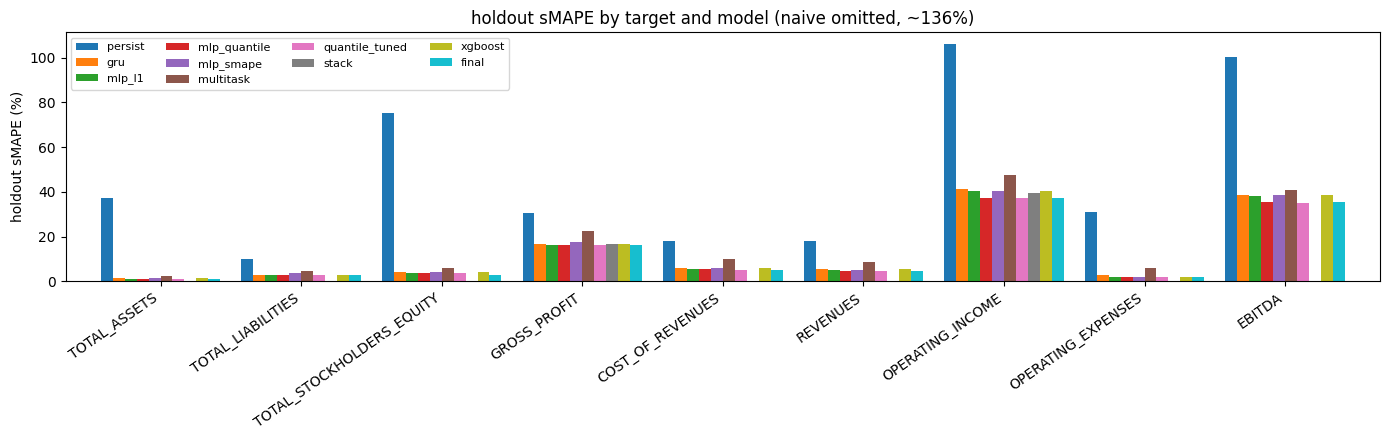

In [16]:
show = [c for c in hold_tab.columns if c != "naive"]
ax = hold_tab.drop(index="AVERAGE")[show].plot.bar(figsize=(14, 4.5), width=0.85)
ax.set_ylabel("holdout sMAPE (%)")
ax.set_title(f"holdout sMAPE by target and model (naive omitted, ~{hold_tab.loc['AVERAGE', 'naive']:.0f}%)")
plt.xticks(rotation=35, ha="right"); plt.legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()

## 11. Submission and limitations

Models were fit on the 80% dev split, so the holdout score above is an honest estimate of test performance.

In [17]:
id_col = orig_name.get(ID, ID)
sub = pd.DataFrame({id_col: test_ids})
for v in TARGET_VARS:
    sub[orig_name["Q0_" + v]] = FINAL[v]["test"]
assert sub.notna().all().all() and np.isfinite(sub.iloc[:, 1:].to_numpy()).all()
sub.to_csv(OUTPUT_DIR / "group_predictions.csv", index=False)
print(os.path.getsize(OUTPUT_DIR / "group_predictions.csv"))
print("wrote predictions.csv", sub.shape); display(sub.head())
for line in [
    "",
    "Limitations of the holdout estimate:",
    "- Models are fit on dev rows only, so the holdout score is an honest estimate for this generator.",
    "- Holdout predictions average N_FOLDS fold models while each dev OOF prediction comes from one model,",
    "  which biases the holdout slightly optimistic relative to CV, independently of any leakage.",
    "- Test-set FEATURES enter row-wise feature construction (transductive; no targets involved).",
    "- Learned statistics are dev-only but are not re-fit inside each CV fold, so slight optimism remains.",
    "- The estimate assumes test rows come from the same generator, scored with the same sMAPE.",
    "- train2.csv rows are now TRAINING data, so they can no longer be used to score anything.",
]:
    print(line)
print(f"Saved predictions to {OUTPUT_DIR / 'group_predictions.csv'}")


5820397
wrote predictions.csv (50000, 10)


,Id,Q0_TOTAL_ASSETS,Q0_TOTAL_LIABILITIES,Q0_TOTAL_STOCKHOLDERS_EQUITY,Q0_GROSS_PROFIT,Q0_COST_OF_REVENUES,Q0_REVENUES,Q0_OPERATING_INCOME,Q0_OPERATING_EXPENSES,Q0_EBITDA
0,56207,3.606892e+09,1.878722e+09,1.728169e+09,2.549319e+08,3.959281e+08,6.594712e+08,-68953200.8,3.205111e+08,-8.821149e+07
1,50182,8.977700e+07,3.895962e+07,5.081738e+07,5.866653e+06,1.171045e+07,1.735898e+07,-14292350.4,2.114379e+07,-1.396839e+07
2,167315,1.950830e+08,6.831896e+07,1.267640e+08,5.888492e+06,5.131398e+06,1.100243e+07,-8206022.8,1.402038e+07,-7.576716e+06
3,146153,5.212356e+07,1.625618e+07,3.586738e+07,1.494819e+06,1.508686e+06,2.897821e+06,-4074994.3,5.458850e+06,-3.491882e+06
4,83472,1.901101e+10,7.440508e+09,1.157050e+10,6.702903e+08,4.588601e+08,1.101135e+09,-448187494.4,1.008097e+09,-6.475400e+08



Limitations of the holdout estimate:
- Models are fit on dev rows only, so the holdout score is an honest estimate for this generator.
- Holdout predictions average N_FOLDS fold models while each dev OOF prediction comes from one model,
  which biases the holdout slightly optimistic relative to CV, independently of any leakage.
- Test-set FEATURES enter row-wise feature construction (transductive; no targets involved).
- Learned statistics are dev-only but are not re-fit inside each CV fold, so slight optimism remains.
- The estimate assumes test rows come from the same generator, scored with the same sMAPE.
- train2.csv rows are now TRAINING data, so they can no longer be used to score anything.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>